# Figure 6 — HMDA classifiers (E1)

Same style/plot code as `2_classifier_analysis.ipynb` (cells copied verbatim); data from `results/<HMDA_RESULTS>/e1_classifiers/`. Recall threshold = 0.90 (paper criterion).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import seaborn as sns


In [2]:
MODEL_LABELS = {
    "mistral-small-2506": "Mistral-S",
    "mistral-large-2512": "Mistral-L",
    "gpt-5-mini": "GPT-5-mini",
    "gpt-5": "GPT-5",
    "llama-3.3-70b-versatile": "Llama-3.3-70B",
}

PROMPT_LABELS = {
    "zero_shot":                "No Context",
    "zero_shot_with_table":     "Table Context",
    "with_examples":            "Examples",
    "with_examples_and_table":  "Examples + Table Context",
}

# ColorBrewer Dark2 — perceptually distinct, print-friendly
okabe_ito = [
    "#E69F00",  # orange
    "#56B4E9",  # sky blue
    "#009E73",  # green
    "#0072B2",  # deep blue
    "#D55E00",  # vermillion
    "#CC79A7",  # pink/purple
    "#000000",  # black
]
_cb = sns.color_palette(okabe_ito, len(PROMPT_LABELS))
PROMPT_COLORS = {label: _cb[i] for i, label in enumerate(PROMPT_LABELS.values())}

# Manual dataset order for the paper
DATASET_ORDER = [
    "hospital",
    "restaurant",
    "sisu",
    "tax"        
]

# Pretty dataset names for titles
DATASET_LABELS = {
    "restaurant": "Restaurant",
    "hospital": "Hospital",
    "tax": "Tax",
    "sisu": "SISU",
}


In [3]:
def apply_pretty_labels(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["model_label"] = df["model"].map(MODEL_LABELS).fillna(df["model"])
    df["prompt_label"] = df["prompt_key"].map(PROMPT_LABELS).fillna(df["prompt_key"])
    df["dataset_label"] = df["dataset"].map(DATASET_LABELS).fillna(df["dataset"])
    return df


def pareto_frontier(points: pd.DataFrame) -> pd.DataFrame:
    """
    True Pareto frontier for maximizing both recall and f1_score.
    A point is kept if it is not dominated by any other point.
    """
    if points.empty:
        return points.copy()

    pts = points.reset_index(drop=True).copy()
    keep = []

    for i, row_i in pts.iterrows():
        dominated = False
        for j, row_j in pts.iterrows():
            if i == j:
                continue

            no_worse = (
                row_j["recall"] >= row_i["recall"]
                and row_j["f1_score"] >= row_i["f1_score"]
            )
            strictly_better = (
                row_j["recall"] > row_i["recall"]
                or row_j["f1_score"] > row_i["f1_score"]
            )

            if no_worse and strictly_better:
                dominated = True
                break

        if not dominated:
            keep.append(i)

    frontier = pts.loc[keep].copy()
    frontier = frontier.sort_values(["recall", "f1_score"]).reset_index(drop=True)

    # Optional: if multiple points have same recall, keep only the best F1
    frontier = frontier.sort_values(["recall", "f1_score"], ascending=[True, False])
    frontier = frontier.groupby("recall", as_index=False).first()
    frontier = frontier.sort_values("recall").reset_index(drop=True)

    return frontier


def build_color_map(model_labels):
    cmap = plt.get_cmap("tab10")
    return {m: cmap(i % 10) for i, m in enumerate(model_labels)}


def build_marker_map(prompt_labels):
    markers = ["o", "s", "^", "D", "P", "X", "v", "<", ">", "*", "h", "8"]
    if len(prompt_labels) > len(markers):
        raise ValueError("Too many prompt labels for available markers.")
    return {p: markers[i] for i, p in enumerate(prompt_labels)}

In [4]:

def plot_performance_grouped(
    df: pd.DataFrame,
    primary_metric: str = "f1_score",
    secondary_metric: str = "recall",
    min_recall: float = 0.80,
    only_success: bool = True,
    bar_width: float = 0.18,
    group_gap: float = 0.30,
    figsize: tuple = (8, 4),
    annotate_values: bool = True,
    save_path: str | None = None,
    dpi: int = 300,
    value_fontsize: float = 11,
    title_y: float = 0.9,
    legend_offset: float = -0.15,
):
    """
    Publication-ready grouped bar chart — one row per dataset (vertical stack).

      filled bars (alpha fill) + thick border = F1 score  (colored by prompt)
      ✕ markers                               = Recall     (same prompt color)
      red dashed line                         = min_recall threshold
    """
    import math

    # ── Publication rcParams ──────────────────────────────────────────────────
    plt.rcParams.update({
        "font.family":           "sans-serif",
        "font.size":             14,
        "axes.titlesize":        16,
        "axes.labelsize":        15,
        "xtick.labelsize":       14,
        "ytick.labelsize":       14,
        "legend.fontsize":       14,
        "legend.title_fontsize": 15,
        "figure.dpi":            150,
        "axes.linewidth":        1.0,
    })

    data = df.copy()

    if only_success and "status" in data.columns:
        data = data[
            data["status"].astype(str).str.lower().str.contains("success", na=False)
        ].copy()

    for col in [primary_metric, secondary_metric, "precision", "accuracy"]:
        if col in data.columns:
            data[col] = pd.to_numeric(data[col], errors="coerce")

    required = ["dataset", "model", "prompt_key", primary_metric]
    missing = [c for c in required if c not in data.columns]
    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    data = apply_pretty_labels(data)
    data = data.dropna(subset=["model_label", "prompt_label", primary_metric])

    # ── Ordered model / prompt lists ─────────────────────────────────────────
    model_order = [v for v in MODEL_LABELS.values() if v in data["model_label"].values]
    model_order += [m for m in data["model_label"].unique() if m not in model_order]

    prompt_order = [v for v in PROMPT_LABELS.values() if v in data["prompt_label"].values]
    prompt_order += [p for p in data["prompt_label"].unique() if p not in prompt_order]

    n_models  = len(model_order)
    n_prompts = len(prompt_order)

    # ── Group x-positions ────────────────────────────────────────────────────
    group_width   = n_prompts * bar_width
    group_centers = np.arange(n_models) * (group_width + group_gap)

    # ── Dataset ordering ─────────────────────────────────────────────────────
    datasets_present = list(data["dataset"].unique())
    datasets = [d for d in DATASET_ORDER if d in datasets_present]
    datasets += [d for d in datasets_present if d not in datasets]

    n_ds = len(datasets)

    fig, axes = plt.subplots(
        n_ds, 1,
        figsize=(figsize[0], figsize[1] * n_ds),
        sharex=True,
        sharey=True,
    )
    fig.subplots_adjust(
        left=0.08, right=0.98,
        top=0.97, bottom=0.06,
        hspace=0.12,
    )
    if n_ds == 1:
        axes = [axes]

    for ax, dataset in zip(axes, datasets):
        ds = data[data["dataset"] == dataset]

        for pi, prompt in enumerate(prompt_order):
            color  = PROMPT_COLORS.get(prompt, f"C{pi}")
            offset = (pi - (n_prompts - 1) / 2) * bar_width
            x_pos  = group_centers + offset

            vals_p, vals_s = [], []
            for model in model_order:
                row = ds[(ds["model_label"] == model) & (ds["prompt_label"] == prompt)]
                vals_p.append(row[primary_metric].iloc[0]   if not row.empty else np.nan)
                vals_s.append(row[secondary_metric].iloc[0] if not row.empty else np.nan)

            # ── Bars: visible alpha fill + thick coloured border ─────────────
            ax.bar(
                x_pos, vals_p,
                width=bar_width * 0.90,
                facecolor=(*color[:3], 0.28),
                edgecolor=color,
                linewidth=2.4,
                zorder=3,
            )

            # ── F1 annotation — above bar in prompt color ─────────────────────
            if annotate_values:
                for xp, val, rec in zip(x_pos, vals_p, vals_s):
                    if np.isnan(val):
                        continue
                    label_y = max(val, 0 if np.isnan(rec) else rec + 0.025) + 0.013
                    ax.text(
                        xp, label_y, f"{val:.2f}",
                        ha="center", va="bottom",
                        fontsize=value_fontsize, color=color, fontweight="bold",
                    )

            # ── Recall ✕ markers in the same prompt color ─────────────────────
            ax.scatter(
                x_pos, vals_s,
                marker="X", s=110, zorder=5,
                color=color, linewidths=0.8,
            )

        # ── Min. recall threshold line ────────────────────────────────────────
        if min_recall is not None:
            ax.axhline(
                min_recall,
                color="#c0392b", linestyle="--",
                linewidth=1.8, zorder=2, alpha=0.90,
            )

        # ── Per-panel styling ─────────────────────────────────────────────────
        x_pad = bar_width * 3
        ax.set_xlim(
            group_centers[0]  - group_width / 2 - x_pad,
            group_centers[-1] + group_width / 2 + x_pad,
        )
        ax.set_ylim(0, 1.16)

        ax.set_title(
            DATASET_LABELS.get(dataset, dataset.capitalize()),
            fontsize=14, fontweight="bold", loc="center", pad=2, y=title_y,
        )

        ax.tick_params(axis="y", labelsize=14, length=4, pad=8)
        ax.tick_params(axis="x", length=4)
        ax.yaxis.set_major_locator(plt.MultipleLocator(0.2))
        ax.yaxis.set_minor_locator(plt.MultipleLocator(0.1))
        ax.grid(True, axis="y", which="major", alpha=0.22, zorder=0, linestyle="--", linewidth=0.8)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
        ax.spines[["left", "bottom"]].set_linewidth(1.0)

    # ── Shared x-axis ticks (bottom row only) ─────────────────────────────────
    axes[-1].set_xticks(group_centers)
    axes[-1].set_xticklabels(model_order, fontsize=15, rotation=15, ha="right")

    # ── Common y-axis label ────────────────────────────────────────────────────
    fig.text(
        0.01, 0.5,
        "F1 Score (bar)  /  Recall (✕)",
        fontsize=15, ha="center", va="center",
        rotation="vertical",
    )

    # ── Legend — anchored just below the bottom axis (axis-relative coords) ───
    prompt_patches = [
        mpatches.Patch(
            facecolor=(*PROMPT_COLORS.get(p, f"C{i}")[:3], 0.28),
            edgecolor=PROMPT_COLORS.get(p, f"C{i}"),
            linewidth=2.4,
            label=p,
        )
        for i, p in enumerate(prompt_order)
    ]
    min_recall_handle = Line2D(
        [0], [0],
        linestyle="--", linewidth=2.0, color="#c0392b",
        label=f"Min. recall = {min_recall:.2f}",
    )

    # Use axes[-1].transAxes so the legend sits a fixed distance below the last panel,
    # independent of figure size / number of datasets
    leg = axes[-1].legend(
        handles=prompt_patches + [min_recall_handle],
        loc="upper center",
        bbox_to_anchor=(0.5, legend_offset),
        bbox_transform=axes[-1].transAxes,
        ncol=3,
        frameon=False,
        fontsize=15,
        title="Prompt strategy",
        title_fontsize=15,
        handlelength=2.2,
        handleheight=1.4,
        columnspacing=1.5,
        handletextpad=0.8,
        labelspacing=0.5,
    )

    if save_path:
        plt.savefig(save_path, dpi=dpi, bbox_inches="tight", facecolor="white")

    plt.show()


In [5]:
def analyse_best_configs(
    df: pd.DataFrame,
    min_recall: float = 0.90,
    only_success: bool = True,
    top_n: int = 5,
) -> None:
    """
    Print a multi-criteria best-configuration analysis:
      1. Per-dataset winner  (highest F1, recall >= min_recall)
      2. Overall ranking     (mean F1 across datasets, recall >= min_recall everywhere)
      3. Most consistent     (lowest std-dev of F1 across datasets)
      4. Highest recall      (mean recall across datasets)
    """
    data = df.copy()
    if only_success and "status" in data.columns:
        data = data[data["status"].astype(str).str.lower().str.contains("success", na=False)]

    for col in ["f1_score", "recall", "precision", "accuracy"]:
        if col in data.columns:
            data[col] = pd.to_numeric(data[col], errors="coerce")

    data = apply_pretty_labels(data)
    data["config"] = data["model_label"] + "  +  " + data["prompt_label"]

    sep = "─" * 72

    # ── 1. Per-dataset winner ─────────────────────────────────────────────────
    print(sep)
    print("  PER-DATASET BEST  (highest F1 with Recall ≥ {:.2f})".format(min_recall))
    print(sep)
    datasets_present = [d for d in DATASET_ORDER if d in data["dataset"].unique()]
    datasets_present += [d for d in data["dataset"].unique() if d not in datasets_present]

    for ds in datasets_present:
        sub = data[(data["dataset"] == ds) & (data["recall"] >= min_recall)]
        label = DATASET_LABELS.get(ds, ds)
        if sub.empty:
            print(f"  {label:<14}  — no config meets recall ≥ {min_recall:.2f}")
        else:
            best = sub.loc[sub["f1_score"].idxmax()]
            print(
                f"  {label:<14}  {best['config']:<35}"
                f"  F1={best['f1_score']:.3f}  Recall={best['recall']:.3f}"
            )

    # ── 2. Overall ranking — mean F1 (recall filter applied per dataset) ──────
    print()
    print(sep)
    print(f"  OVERALL RANKING  (mean F1 across datasets, Recall ≥ {min_recall:.2f} in every dataset)")
    print(sep)

    n_datasets = data["dataset"].nunique()

    agg = (
        data[data["recall"] >= min_recall]
        .groupby("config")
        .agg(
            datasets_passing=("dataset", "nunique"),
            mean_f1=("f1_score", "mean"),
            min_f1=("f1_score", "min"),
            mean_recall=("recall", "mean"),
        )
        .reset_index()
    )
    # Only configs that pass the recall filter in ALL datasets
    agg_all = agg[agg["datasets_passing"] == n_datasets].sort_values("mean_f1", ascending=False)

    if agg_all.empty:
        print("  No single config passes the recall threshold across all datasets.")
    else:
        for rank, (_, row) in enumerate(agg_all.head(top_n).iterrows(), 1):
            print(
                f"  #{rank}  {row['config']:<35}"
                f"  mean F1={row['mean_f1']:.3f}"
                f"  min F1={row['min_f1']:.3f}"
                f"  mean Recall={row['mean_recall']:.3f}"
            )

    # ── 3. Most consistent — lowest std-dev of F1 (all datasets, no recall filter) ──
    print()
    print(sep)
    print("  MOST CONSISTENT  (lowest F1 std-dev across datasets, no recall filter)")
    print(sep)

    std_agg = (
        data.groupby("config")
        .agg(
            datasets=("dataset", "nunique"),
            mean_f1=("f1_score", "mean"),
            std_f1=("f1_score", "std"),
        )
        .reset_index()
    )
    std_agg = std_agg[std_agg["datasets"] == n_datasets].sort_values(
        ["std_f1", "mean_f1"], ascending=[True, False]
    )
    for rank, (_, row) in enumerate(std_agg.head(top_n).iterrows(), 1):
        print(
            f"  #{rank}  {row['config']:<35}"
            f"  mean F1={row['mean_f1']:.3f}"
            f"  std={row['std_f1']:.3f}"
        )

    # ── 4. Highest recall ─────────────────────────────────────────────────────
    print()
    print(sep)
    print("  HIGHEST RECALL  (mean recall across all datasets, top configs)")
    print(sep)

    rec_agg = (
        data.groupby("config")
        .agg(
            datasets=("dataset", "nunique"),
            mean_recall=("recall", "mean"),
            min_recall_val=("recall", "min"),
            mean_f1=("f1_score", "mean"),
        )
        .reset_index()
    )
    rec_agg = rec_agg[rec_agg["datasets"] == n_datasets].sort_values(
        ["mean_recall", "mean_f1"], ascending=[False, False]
    )
    for rank, (_, row) in enumerate(rec_agg.head(top_n).iterrows(), 1):
        print(
            f"  #{rank}  {row['config']:<35}"
            f"  mean Recall={row['mean_recall']:.3f}"
            f"  min Recall={row['min_recall_val']:.3f}"
            f"  mean F1={row['mean_f1']:.3f}"
        )

    print(sep)

In [6]:
# HMDA results: reads ONLY small result files under results/<HMDA_RESULTS>/ (never data CSVs).
# Environment: HMDA_RESULTS (default "hmda"; e.g. "hmda_v2"), HMDA_MODELS (model manifest).
import os
from pathlib import Path
import pandas as pd
import yaml

ROOT = Path.cwd()
while not (ROOT / "experiments").is_dir():
    ROOT = ROOT.parent
RESULTS_DIR = ROOT / "results" / os.environ.get("HMDA_RESULTS", "hmda")
FIG_DIR = RESULTS_DIR / "figures"
import sys
sys.path.insert(0, str(ROOT / "notebooks" / "results_analysis"))
FIG_DIR.mkdir(parents=True, exist_ok=True)
MANIFEST = yaml.safe_load(
    (ROOT / os.environ.get("HMDA_MODELS", "experiments/configs/hmda_models.yaml")).read_text()
)

# Dataset group (defaults: HMDA). Paper datasets: RESULTS_DATASETS=hospital,restaurant,sisu,tax
HMDA_DATASET_ORDER = os.environ.get("RESULTS_DATASETS", "hmdaz,hmda_checks").split(",")
HMDA_DATASET_LABELS = {
    "hmdaz": "HMDAZ", "hmda_checks": "HMDA Checks", "hospital": "Hospital",
    "restaurant": "Restaurant", "sisu": "SISU", "tax": "Tax",
}
GROUP_LABEL = os.environ.get("RESULTS_LABEL", "HMDA")
ROW_NOTE = os.environ.get("ROW_NOTE", "first 1,000,000 rows per dataset")
FIG_PREFIX = os.environ.get("FIG_PREFIX", "hmda")
# Model order/labels follow the manifest (paper_name)
HMDA_MODEL_LABELS = {model["slug"]: model["paper_name"] for model in MANIFEST["models"]}
print(f"Results: {RESULTS_DIR}")


def load_hmda_results(experiment_dir: str) -> pd.DataFrame:
    """Concatenate results_summary.csv of every run; per variant keep the latest
    successful attempt (else the latest failure)."""
    frames = []
    for path in sorted((RESULTS_DIR / experiment_dir).glob("*/results_summary.csv")):
        frame = pd.read_csv(path)
        frame["run_dir"] = path.parent.name
        frames.append(frame)
    if not frames:
        raise FileNotFoundError(f"No results under {RESULTS_DIR / experiment_dir}")
    results = pd.concat(frames, ignore_index=True)
    results["_ok"] = results["status"] == "success"
    results = results.sort_values(["_ok", "run_dir"])
    results = results.drop_duplicates(["dataset", "variant_name"], keep="last").drop(columns="_ok")
    failed = results[results["status"] != "success"]
    if not failed.empty:
        print("Failed variants (excluded from plots):")
        print(failed[["dataset", "variant_name", "status"]].to_string(index=False))
    return results


Results: /home/junio/source/norma/results/v3


In [7]:
MODEL_LABELS = HMDA_MODEL_LABELS
DATASET_ORDER = HMDA_DATASET_ORDER
DATASET_LABELS = HMDA_DATASET_LABELS

df = load_hmda_results("e1_classifiers")
df[["dataset", "model", "prompt_key", "precision", "recall", "f1_score", "status"]]

,dataset,model,prompt_key,precision,recall,f1_score,status
0,hmda_checks,deepseek/deepseek-v4-flash,zero_shot,0.5823,1.0000,0.7360,success
1,hmda_checks,deepseek/deepseek-v4-flash,zero_shot_with_table,0.7459,0.9891,0.8505,success
2,hmda_checks,deepseek/deepseek-v4-flash,with_examples,0.5823,1.0000,0.7360,success
3,hmda_checks,deepseek/deepseek-v4-flash,with_examples_and_table,0.7054,0.9891,0.8235,success
4,hmda_checks,openai/gpt-6-luna,zero_shot,0.5897,1.0000,0.7419,success
...,...,...,...,...,...,...,...
139,tax,qwen/qwen3.8-2.4t-a95b,with_examples_and_table,0.5455,1.0000,0.7059,success
140,tax,anthropic/claude-sonnet-5.5,zero_shot,0.6000,1.0000,0.7500,success
141,tax,anthropic/claude-sonnet-5.5,zero_shot_with_table,0.3333,1.0000,0.5000,success
142,tax,anthropic/claude-sonnet-5.5,with_examples,0.5000,1.0000,0.6667,success


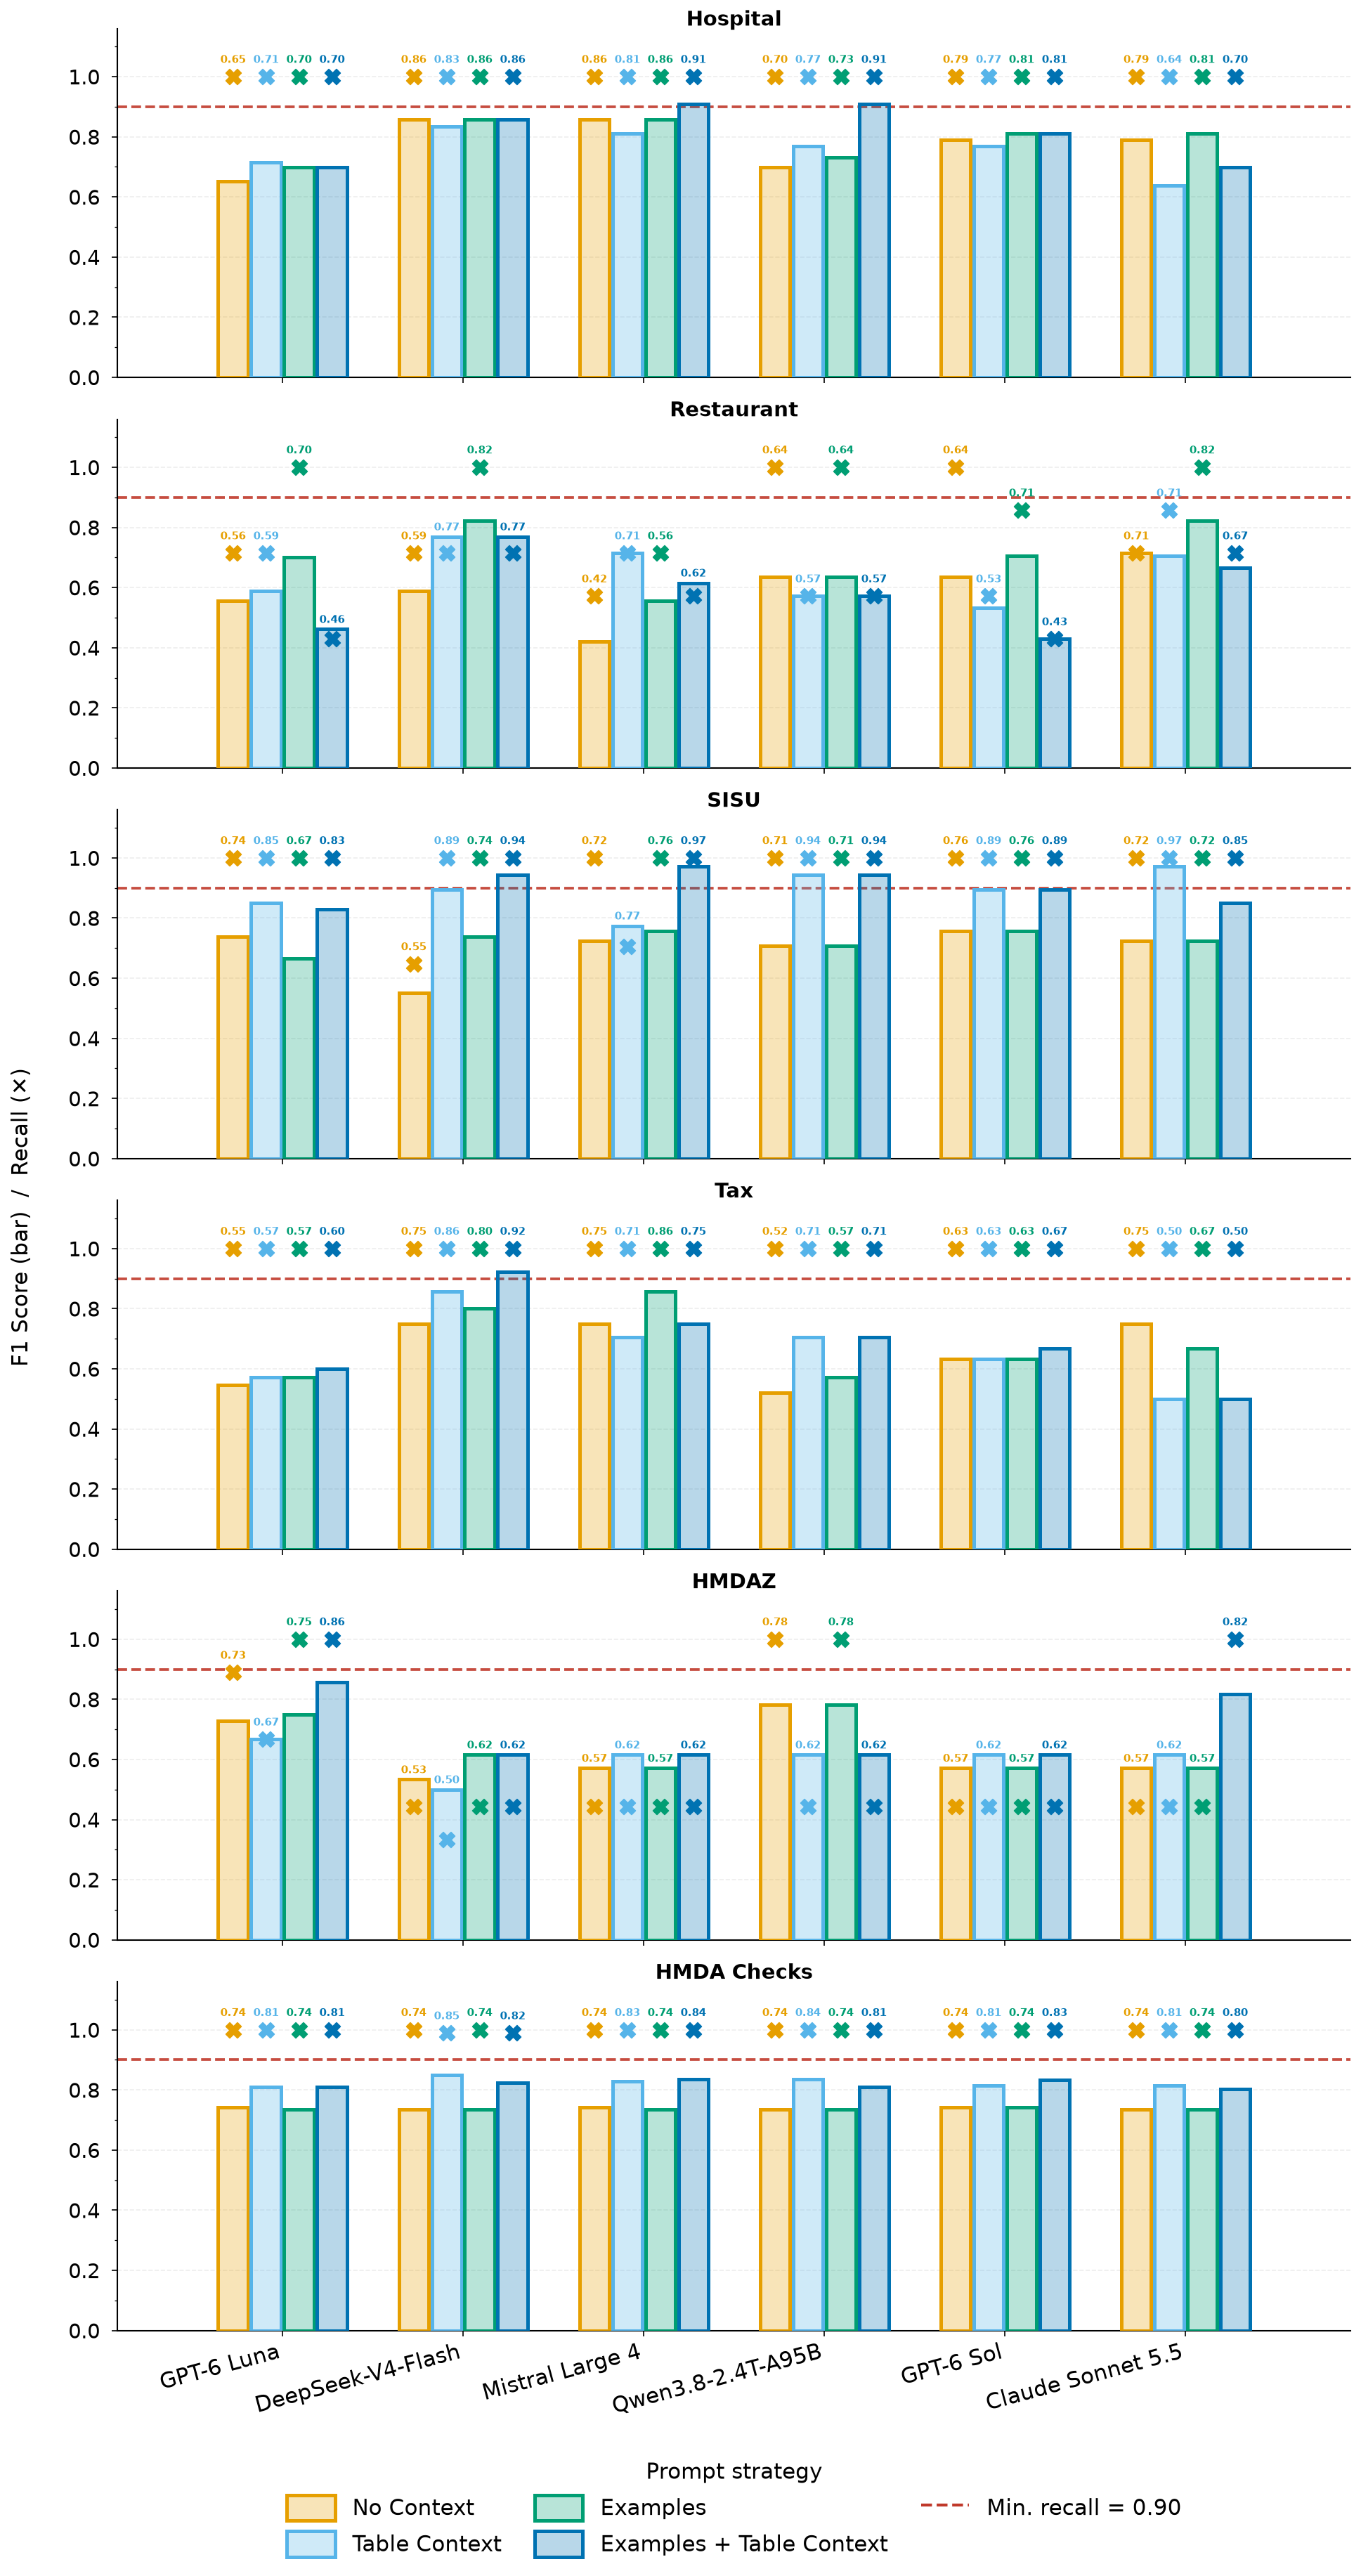

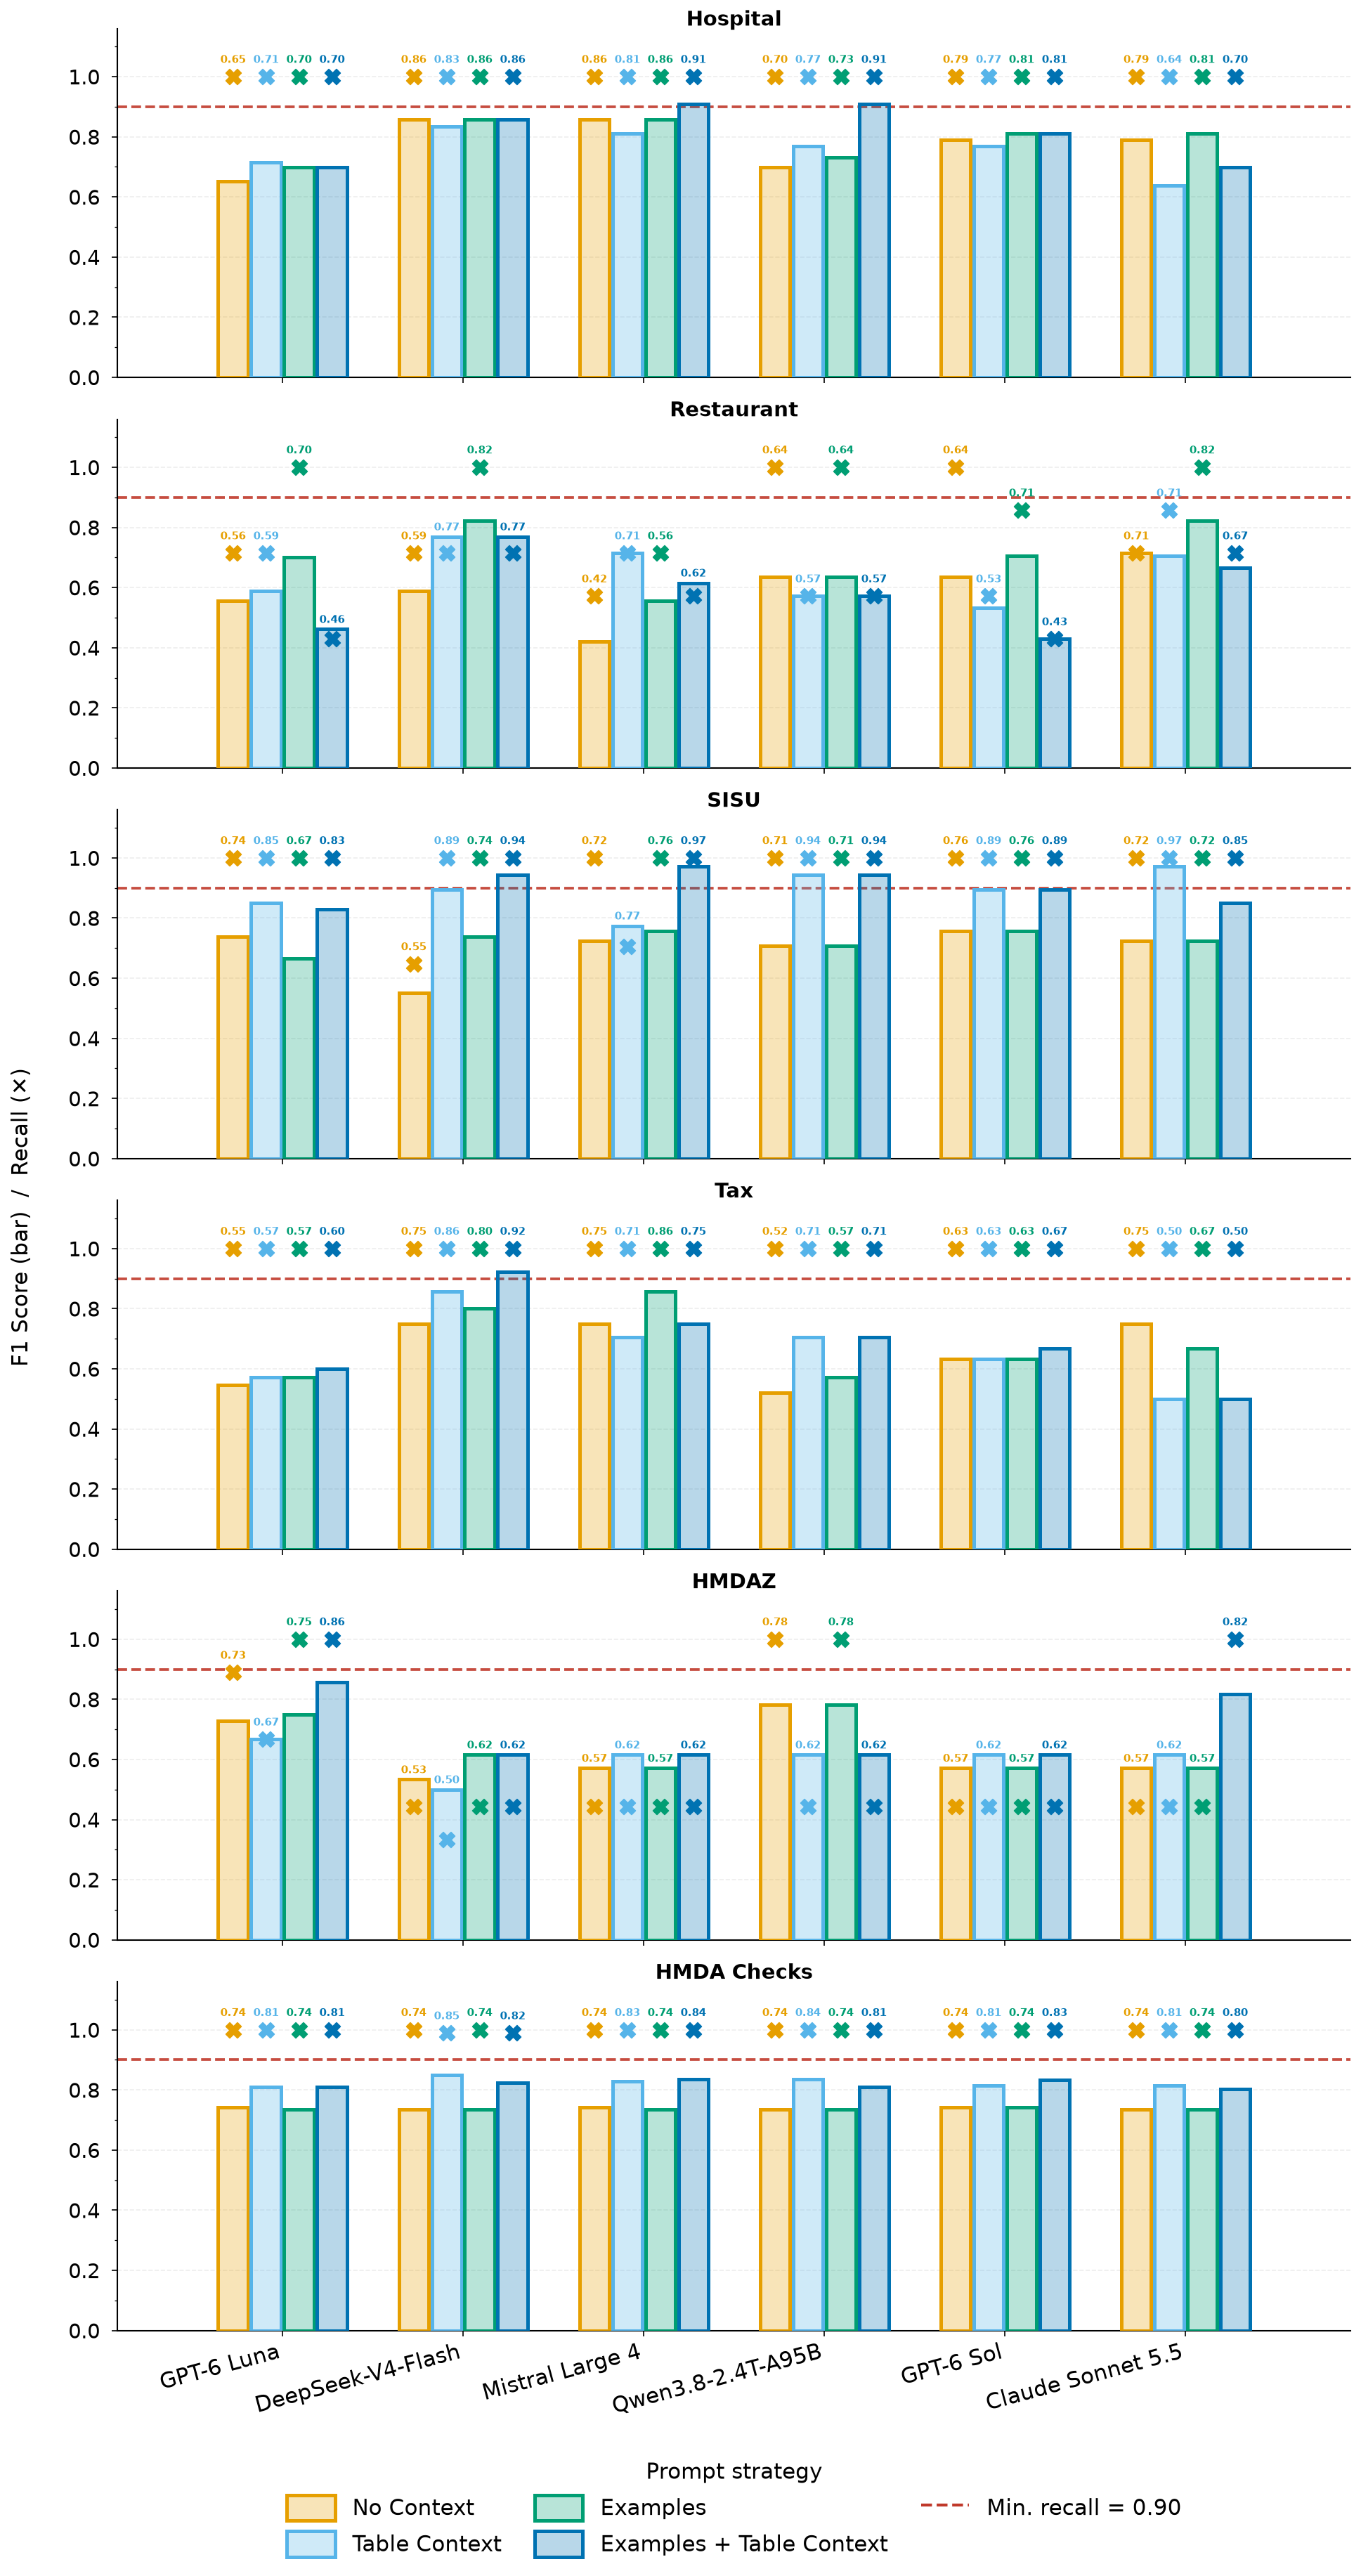

In [8]:
for suffix in ("pdf", "png"):
    plot_performance_grouped(
        df,
        primary_metric="f1_score",
        secondary_metric="recall",
        min_recall=0.90,
        only_success=True,
        bar_width=0.19,
        group_gap=0.28,
        figsize=(13, 4),
        annotate_values=True,
        save_path=str(FIG_DIR / f"{FIG_PREFIX}_fig6_classifiers.{suffix}"),
        dpi=300,
        value_fontsize=7,
        title_y=1.0,
        legend_offset=-0.32,
    )

In [9]:
# Paper selection criterion: among configs with recall >= 0.90, pick the highest F1.
table = apply_pretty_labels(df[df["status"] == "success"])
table = table[["dataset", "model_label", "prompt_label", "precision", "recall", "f1_score"]]
table["recall_ge_0_90"] = table["recall"] >= 0.90
table = table.sort_values(["dataset", "model_label", "prompt_label"])
table.to_csv(FIG_DIR / f"{FIG_PREFIX}_e1_classifier_table.csv", index=False)

selected = (
    table[table["recall_ge_0_90"]]
    .sort_values("f1_score", ascending=False)
    .groupby("dataset")
    .head(1)
)
selected.to_csv(FIG_DIR / f"{FIG_PREFIX}_e1_selected.csv", index=False)
display(table)
display(selected)
analyse_best_configs(df, min_recall=0.90, top_n=5)

,dataset,model_label,prompt_label,precision,recall,f1_score,recall_ge_0_90
22,hmda_checks,Claude Sonnet 5.5,Examples,0.5823,1.0,0.7360,True
23,hmda_checks,Claude Sonnet 5.5,Examples + Table Context,0.6715,1.0,0.8035,True
20,hmda_checks,Claude Sonnet 5.5,No Context,0.5823,1.0,0.7360,True
21,hmda_checks,Claude Sonnet 5.5,Table Context,0.6866,1.0,0.8142,True
2,hmda_checks,DeepSeek-V4-Flash,Examples,0.5823,1.0,0.7360,True
...,...,...,...,...,...,...,...
133,tax,Mistral Large 4,Table Context,0.5455,1.0,0.7059,True
138,tax,Qwen3.8-2.4T-A95B,Examples,0.4000,1.0,0.5714,True
139,tax,Qwen3.8-2.4T-A95B,Examples + Table Context,0.5455,1.0,0.7059,True
136,tax,Qwen3.8-2.4T-A95B,No Context,0.3529,1.0,0.5217,True


,dataset,model_label,prompt_label,precision,recall,f1_score,recall_ge_0_90
117,sisu,Claude Sonnet 5.5,Table Context,0.9444,1.0000,0.9714,True
123,tax,DeepSeek-V4-Flash,Examples + Table Context,0.8571,1.0000,0.9231,True
63,hospital,Mistral Large 4,Examples + Table Context,0.8333,1.0000,0.9091,True
31,hmdaz,GPT-6 Luna,Examples + Table Context,0.7500,1.0000,0.8571,True
1,hmda_checks,DeepSeek-V4-Flash,Table Context,0.7459,0.9891,0.8505,True
94,restaurant,Claude Sonnet 5.5,Examples,0.7000,1.0000,0.8235,True


────────────────────────────────────────────────────────────────────────
  PER-DATASET BEST  (highest F1 with Recall ≥ 0.90)
────────────────────────────────────────────────────────────────────────
  Hospital        Mistral Large 4  +  Examples + Table Context  F1=0.909  Recall=1.000
  Restaurant      DeepSeek-V4-Flash  +  Examples       F1=0.824  Recall=1.000
  SISU            Mistral Large 4  +  Examples + Table Context  F1=0.971  Recall=1.000
  Tax             DeepSeek-V4-Flash  +  Examples + Table Context  F1=0.923  Recall=1.000
  HMDAZ           GPT-6 Luna  +  Examples + Table Context  F1=0.857  Recall=1.000
  HMDA Checks     DeepSeek-V4-Flash  +  Table Context  F1=0.851  Recall=0.989

────────────────────────────────────────────────────────────────────────
  OVERALL RANKING  (mean F1 across datasets, Recall ≥ 0.90 in every dataset)
────────────────────────────────────────────────────────────────────────
  #1  Qwen3.8-2.4T-A95B  +  Examples       mean F1=0.694  min F1=0.571  mean 

In [10]:
# E1 LaTeX table (paper Table 3 style); module: notebooks/results_analysis/hmda_latex.py
from hmda_latex import e1_table

latex = e1_table(
    apply_pretty_labels(df[df["status"] == "success"]),
    list(PROMPT_LABELS.values()), list(MODEL_LABELS.values()),
    HMDA_DATASET_ORDER, HMDA_DATASET_LABELS, GROUP_LABEL, ROW_NOTE,
)
(FIG_DIR / f"{FIG_PREFIX}_e1_classifiers.tex").write_text(latex, encoding="utf-8")
print(latex)

\begin{table*}[t]
  \centering
  \small
  \setlength{\tabcolsep}{3.5pt}
  \begin{tabular}{l@{\hspace{0.6em}}rrr@{\hspace{0.6em}}rrr@{\hspace{0.6em}}rrr@{\hspace{0.6em}}rrr}
  \toprule
  & \multicolumn{3}{c}{\shortstack{No\\Context}} & \multicolumn{3}{c}{\shortstack{Table\\Context}} & \multicolumn{3}{c}{Examples} & \multicolumn{3}{c}{\shortstack{Examples +\\Table Context}} \\
  \cmidrule(lr){2-4} \cmidrule(lr){5-7} \cmidrule(lr){8-10} \cmidrule(lr){11-13}
  \textbf{Model} & P & R & F$_1$ & P & R & F$_1$ & P & R & F$_1$ & P & R & F$_1$ \\
  \midrule
  \multicolumn{13}{l}{\textit{Hospital}} \\
  ~~GPT-6 Luna & 0.48 & \textbf{1.00} & 0.65$^\dagger$ & 0.56 & \textbf{1.00} & 0.71$^\dagger$ & 0.54 & \textbf{1.00} & 0.70$^\dagger$ & 0.54 & \textbf{1.00} & 0.70$^\dagger$ \\
  ~~DeepSeek-V4-Flash & \textbf{0.75} & \textbf{1.00} & \textbf{0.86}$^\dagger$ & \textbf{0.71} & \textbf{1.00} & \textbf{0.83}$^\dagger$ & \textbf{0.75} & \textbf{1.00} & \textbf{0.86}$^\dagger$ & 0.75 & \textbf{1.00} & 0.8